In [1]:
'''
making training lists for the random forest
'''

'\nmaking training lists for the random forest\n'

In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp
import corner
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

Matplotlib is building the font cache; this may take a moment.


In [4]:
concat = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat')

In [5]:
bad_lcs_from_inspection = [310766,  25081, 86944, 276065,  21774,294153,62029,141910,  276055, 229385, 210263, 270334,  15810, 231282, 230962,
       315473, 276064, 309636, 295034, 235364, 333117, 100503,  21251,
       267173,261542, 145997, 203084, 169009,295025,342287, 282051,  86945,  86943,140405, 104411, 261536, 182966,
        86963, 28168, 213968, 261815,  276066, 335735, 262197, 168084, 129920, 182967, 99704, 230142, 215184, 323976, 105564, 91066, 261543, 166793, 229899, 87155, 48224, 29035, 107843, 291306, 195807, 192110,232730, 272321 ]

In [6]:
concat['global_noise_over_average']=concat['noise_global_brightening']/concat['local_average_outside_brightening']

In [7]:
bad_lcs_from_cut = concat[concat['global_noise_over_average']>.16].index.values

In [82]:
len(bad_lcs_from_cut)

1772

In [8]:
lc_names_bad = []
for index in np.hstack((bad_lcs_from_inspection, bad_lcs_from_cut)):
    df_row = concat.loc[index]
    lc_filename = 'lightcurve_'+df_row['filename'][:-1]+'_'+str(df_row['quadrant'])+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+'.csv'
    lc_names_bad.append(lc_filename)
lc_names_bad = np.unique(lc_names_bad)

In [84]:
lc_names_bad


array(['lightcurve_ztf_20221020138241_000686_zi_c02_x_0018_2_2455_2959.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c03_x_0003_1_0613_0345.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c03_x_0005_1_0613_0345.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c03_x_0024_1_0613_0345.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c03_x_0028_1_0613_0345.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c03_x_0029_1_0613_0345.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c08_x_0016_3_2365_1928.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c08_x_0022_3_2365_1928.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c12_x_0026_2_2602_2642.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c12_x_0026_3_2836_0421.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c12_x_0026_3_2877_1508.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c12_x_0027_2_2739_1637.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c12_x_0027_3_2815_1741.csv',

In [14]:
len(lc_names_bad)

194

In [85]:
np.save( '/lustre/lrspec/ZTF_data/random_forest_training/lc_names_bad',lc_names_bad)

In [34]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [9]:
concat['concat_index_copy']=concat.index.values

In [32]:
different_stars

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,...,noise_global_dimming,local_average_outside_dimming,height_dimming,FWHM_dimming,signal_local_dimming,central_point_dimming,quadrant,num_in_file_in_star,global_noise_over_average,concat_index_copy
310763,310763,0,15,ztf_20221020138241_000686_zi_c15_x_0014.,4,pos,2430.500000,546.000000,10,555.0,...,31.274989,974.400173,-54.904445,2.0,9.560814,2432.0,4,1.0,0.032075,310763
310764,310764,1,2,ztf_20221020138241_000686_zi_c15_x_0014.,4,both,379.196191,560.422245,104,570.0,...,27.563829,642.475245,-37.807032,2.0,7.743621,400.0,4,1.0,0.042987,310764
310765,310765,2,17,ztf_20221020138241_000686_zi_c15_x_0014.,4,pos,2725.937500,889.375000,16,899.0,...,36.866134,1212.242759,-146.108970,6.0,25.509441,2728.0,4,1.0,0.030435,310765
310767,310767,4,0,ztf_20221020138241_000686_zi_c15_x_0014.,4,pos,81.375000,1574.750000,8,1583.0,...,30.897763,954.920632,-64.009072,3.0,13.032596,85.0,4,1.0,0.032439,310767
310768,310768,5,1,ztf_20221020138241_000686_zi_c15_x_0014.,4,pos,141.100000,1922.200000,10,1932.0,...,52.317205,1782.176890,-62.818003,2.0,10.694495,141.0,4,2.0,0.029325,310768
310769,310769,6,7,ztf_20221020138241_000686_zi_c15_x_0014.,4,pos,867.400000,1922.000000,5,1932.0,...,52.082882,1804.478528,-12.899792,1.0,3.591628,867.0,4,2.0,0.028950,310769
310770,310770,7,10,ztf_20221020138241_000686_zi_c15_x_0014.,4,both,1007.375000,2029.125000,37,2039.0,...,33.925985,812.968499,-91.882683,7.0,22.887317,1021.0,4,2.0,0.041778,310770
310771,310771,8,11,ztf_20221020138241_000686_zi_c15_x_0014.,4,pos,1093.928571,2029.500000,14,2039.0,...,33.936221,820.656145,-63.695940,3.0,12.715695,1098.0,4,2.0,0.041336,310771
310772,310772,9,4,ztf_20221020138241_000686_zi_c15_x_0014.,4,pos,555.000000,2177.000000,3,2187.0,...,23.996127,623.696225,-8.527585,1.0,2.920203,574.0,4,1.0,0.038466,310772
310773,310773,10,6,ztf_20221020138241_000686_zi_c15_x_0014.,4,pos,806.125000,2837.125000,16,2847.0,...,33.519592,1054.316848,-30.871230,1.0,5.556188,811.0,4,2.0,0.031826,310773


Index 135771
[135770 135772]


IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

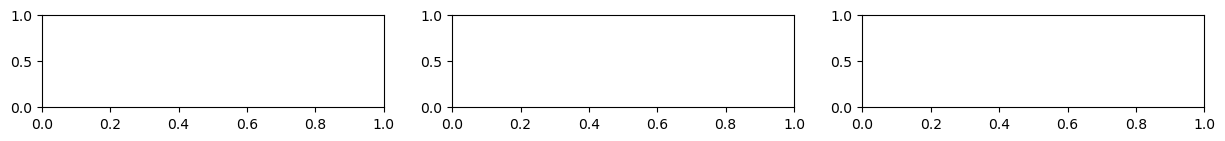

In [10]:

for index in np.hstack((bad_lcs_from_inspection, bad_lcs_from_cut))[585:]:
    group = concat[concat['filename']==concat.loc[index, 'filename']]
    quadgroup = group[group['quad']==concat.loc[index, 'quad']]
    different_stars = quadgroup[quadgroup['closest_x']!=concat.loc[index, 'closest_x']]
    print("Index "+str(index))
    different_stars = different_stars.drop_duplicates(subset="closest_x")
    print(different_stars['concat_index_copy'].values, flush=True)
    rff.plot_small_multiples_lcs(different_stars, concat, 'concat_index_copy')
    plt.show()
    # break
    # lc_filename = 'lightcurve_'+df_row['filename'][:-1]+'_'+str(df_row['quadrant'])+'_'+str(int(df_row['closest_x']))+'_'+str(int(df_row['closest_y']))+'.csv'
    # lc_names_bad.append(lc_filename)
# lc_names_bad = np.unique(lc_names_bad)

In [61]:
len(np.hstack((bad_lcs_from_inspection, bad_lcs_from_cut)))

1837

In [60]:
np.where(np.hstack((bad_lcs_from_inspection, bad_lcs_from_cut))==135771)

(array([585]),)

In [11]:
goodlcs = [310767 ,310772, 310765
,25091
,25104
,25190
,86964 ,86967 ,86969 
,276069 ,276071 ,21786, 21791 ,21792
,  21793
,294130 ,294132 ,294133
,61820
,61889
,61981
,141747 ,141760 ,141766
,276071 , 276075, 276079
,229314 ,229317 ,229321
,210276 ,210277 ,210278
,270300 ,270304 ,270306
,231300 ,231306 ,231309
,230942 ,230945 ,230948
,315470 ,315472 ,315474 
,276073 ,276075 ,276079
,309644 ,309653 ,309663 
,295038, 295041, 295042
,235342, 235344, 235355
,333116, 333118, 333121
,100476, 100490, 100492
,21224 ,21238 ,21241 
,261559, 261561, 261565
,145994, 145998, 145999
,203155, 203174, 203186
,168968, 168971, 168972 
,295038, 295041, 295042
,342294, 342296, 342300 
,282059, 282060, 282062
,86967, 86969 ,86971
,86967, 86969 ,86971
,140349, 140360 ,140362
,104332, 104338 ,104340 
,261559, 261561 ,261565
,182933, 182935 ,182936
,86964 ,86967 ,86969
,28162 ,28163 ,28164 
,213910, 213912, 213914 
,261813, 261816,  261825
,276073, 276075, 276079
,335791, 335792, 335797
, 262181, 262199, 262200
,168073, 168074, 168087
,129921, 129924, 129925 
,182933, 182935, 182936 
,99647 ,99651 ,99658
,230113, 230114, 230116
,215202, 215203, 215205
,91084 ,91087 ,91093
,261559, 261561, 261565
,166669, 166681, 166689
,229894, 229895, 229896
,87161 ,87180 ,87193 
,48230 ,48231 ,48234
,29022 ,29024 ,29026
,107830, 107832, 107834
,291334, 291335, 291336
,195834, 195835, 195836
,6702 ,6704 ,6705
,12197, 12202, 12205
,12197, 12202, 12205
,12197, 12202, 12205
,12189, 12197, 12202 ,12205
,12189, 12197, 12202
,22091
, 22098 ,22099
,32808
, 32810, 32814
,32808
, 32810, 32814
,33174 ,33175 ,33179
,34025 ,34026
,34047
,38003 ,38005 ,38008
,43697 ,43699 ,43702
,43981 ,43985 ,43987
,44123 ,44127 ,44169
,46395 ,46398 ,46405 
,48797 ,48805 ,48816
,53716 ,53717 ,53721
,61291 ,61299 ,61303
,61757 ,61763 ,61792
,67250 , 67253
,68593 ,68594 ,68597
,69042 ,69043 ,69045 
,72314 ,72341 ,72342
,73519 ,73522 ,73524
,73906 ,73907 ,73936
,76659 ,76660 ,76663
,77065 ,77066 ,77126
,81405
, 81406, 81409
,81820 ,81823 ,81856
,82321 ,82326 ,82335
,87633 ,87635 ,87637 
,99885 ,99887 ,99888 
,99891 ,99897 ,99901
,103057 ,103066 ,103072
,111591 ,111593 ,111595
,111976 ,111977 ,111979 
,111977 ,111979 ,111981
,120967 ,120968 ,120972 
,121130 ,121132 ,121133 
,121628 , 121633, 121677 
,121628 ,121629 ,121633
,121767 ,121775 ,121781
,121815 ,121818 ,121819
,132138 ,132139 ,132154 
,133386 ,133390 ,133392
]

In [75]:
def plot_small_multiples_lcs(df):
    wid = 10
    figcols = 3
    figrows = 1 + len(df) // figcols
    fig, ax = plt.subplots(figrows, figcols, figsize=(figcols * 5, figrows*1.2))
    for i in range(figrows):
        for j in range(figcols):
            index = figcols * i + j
            if index < len(df):
                tot, maxols = rff.get_tot_csv(concat, df.iloc[index]['concat_index_copy'])
                ax[i,j].set_title(str(index))
                ax[i,j].plot(tot, '.', ms=2)
                ax[i,j].set_xticks([])

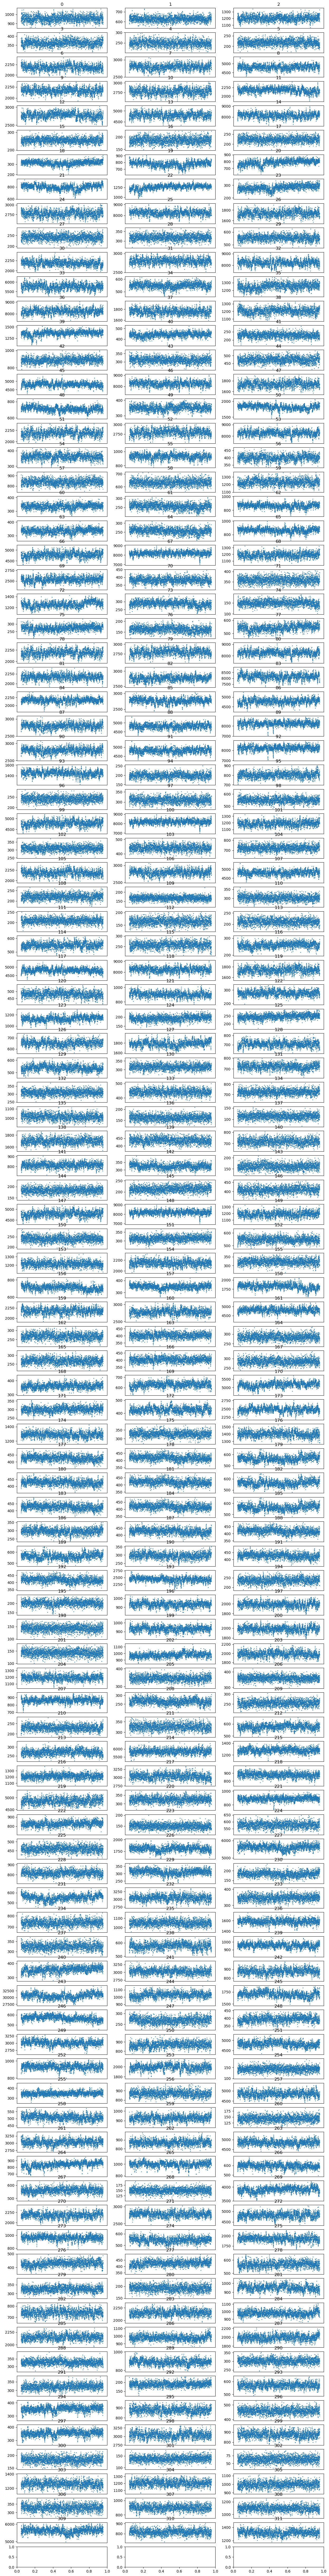

In [78]:
plot_small_multiples_lcs(concat.loc[goodlcs])

In [12]:
lc_names_good = []
for index in goodlcs:
    df_row = concat.loc[index]
    lc_filename = 'lightcurve_'+df_row['filename'][:-1]+'_'+str(df_row['quadrant'])+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+'.csv'
    lc_names_good.append(lc_filename)
lc_names_good = np.unique(lc_names_good)

In [80]:
len(lc_names_good)

267

In [81]:
np.save('/lustre/lrspec/ZTF_data/random_forest_training/lc_names_good', lc_names_good)

In [72]:
lc_names_good

array(['lightcurve_ztf_20221020138241_000686_zi_c02_x_0018_2_290_1816.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c02_x_0018_2_316_2097.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c02_x_0018_2_797_937.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c03_x_0024_1_2989_276.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c03_x_0024_1_708_372.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c08_x_0016_3_329_2918.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c08_x_0016_3_43_1074.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c08_x_0016_3_608_1695.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c08_x_0022_3_292_528.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c08_x_0022_3_329_2918.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c08_x_0022_3_608_1695.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c12_x_0026_3_626_468.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c12_x_0026_3_87_1032.csv',
       'lightcurve

In [13]:
good = concat.loc[goodlcs]

In [97]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [14]:
good = rff.add_band(good)

In [15]:
bad = concat.loc[np.hstack((bad_lcs_from_inspection, bad_lcs_from_cut))]

In [16]:
bad = rff.add_band(bad)

In [17]:
plt.hist(concat_band_unique['Band'], label='All observations', alpha=.5)
plt.hist(bad['Band'], label='Good training data', alpha=.5)
plt.hist(good['Band'], label='Bad training data', alpha=.5)
plt.legend()
plt.title("Band distribution for random forest training data")
plt.xlabel("Band")
plt.ylabel("Counts")

NameError: name 'concat_band_unique' is not defined

In [29]:
concat_band = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat_with_band')

In [30]:
concat_band_unique = concat_band.drop_duplicates(subset='filename')

In [109]:
concat_band_unique

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,...,noise_local_dimming,noise_global_dimming,local_average_outside_dimming,height_dimming,FWHM_dimming,signal_local_dimming,central_point_dimming,quadrant,num_in_file_in_star,Band
0,0,0,0,0,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,686.500000,907.000000,2,...,216.645045,171.717937,6334.883496,-263.138867,2.0,20.657016,703.0,4,6.0,i
8,8,8,0,19,ztf_20221020148032_000686_zg_c14_x_0017.,1,pos,1849.000000,1058.500000,2,...,248.853572,237.366754,7520.139160,-666.707520,9.0,67.204060,1852.0,1,3.0,g
28,28,28,0,3,ztf_20221020297847_000449_zr_c13_x_0026.,3,pos,271.000000,945.000000,3,...,66.397888,79.420315,2006.381214,-57.421497,5.0,15.508041,272.0,3,6.0,r
50,50,50,0,3,ztf_20221020138241_000686_zi_c03_x_0026.,3,pos,566.500000,2204.000000,2,...,41.283352,44.390728,1443.085463,-77.344496,3.0,14.375040,569.0,3,2.0,i
63,63,63,0,3,ztf_20221020154120_000640_zi_c07_x_0012.,4,pos,380.666667,623.555556,9,...,193.703963,184.464721,6697.253589,-340.756519,1.0,18.459592,395.0,4,4.0,i
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
239604,239604,239604,0,0,ztf_20221020294271_000449_zr_c08_x_0019.,1,pos,2303.500000,2462.000000,2,...,16.129950,16.281475,465.562684,-27.045350,1.0,5.200514,2306.0,1,1.0,r
248768,248768,248768,0,0,ztf_20221020157697_000640_zi_c06_x_0020.,4,pos,127.000000,1944.000000,3,...,69.198059,64.696892,2398.710888,-132.515576,1.0,11.511541,144.0,4,1.0,i
255683,255683,255683,0,4,ztf_20221020294271_000449_zr_c11_x_0018.,4,both,2401.500000,217.375000,7,...,123.277641,114.071404,4573.066201,-115.176064,7.0,32.076188,2421.0,4,3.0,r
265380,265380,265380,0,0,ztf_20221020157697_000640_zi_c06_x_0003.,1,pos,0.000000,373.000000,3,...,33.197813,34.689257,1223.320847,-881.954362,0.0,0.000000,0.0,1,1.0,i


In [113]:
'ztf_20221020138241_000686_zi_c03_x_0026.'[22:25]

'686'

In [19]:
def add_field(df):
    field = []
    for i, row in df.iterrows():
        field.append(row['filename'][22:25])
    df["Field"] = field
    return df

In [31]:
concat_band_unique = add_field(concat_band_unique)

/tmp/ipykernel_53616/3988502432.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Field"] = field


In [20]:
bad = add_field(bad)

In [21]:
good = add_field(good)

Text(0, 0.5, 'Counts')

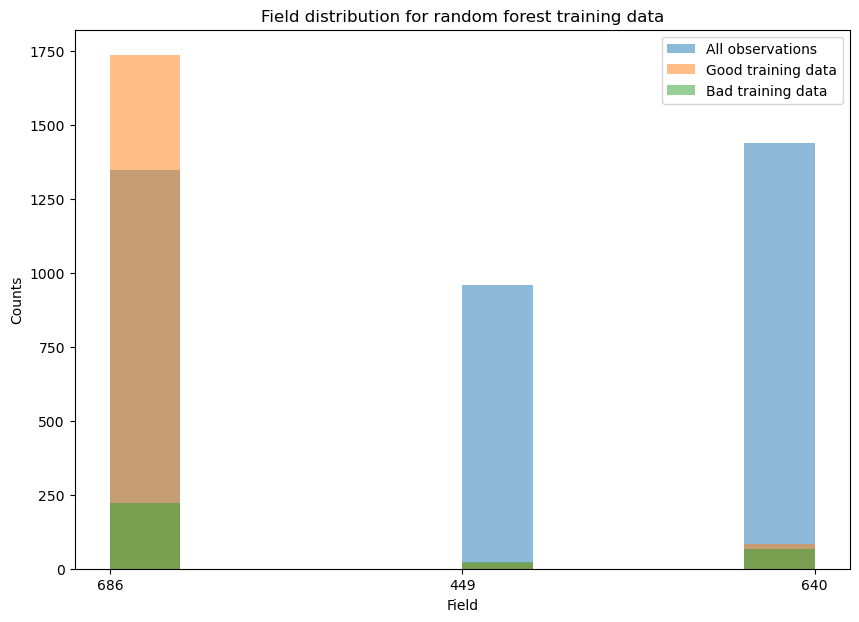

In [123]:
plt.hist(concat_band_unique['Field'], label='All observations', alpha=.5)
plt.hist(bad['Field'], label='Good training data', alpha=.5)
plt.hist(good['Field'], label='Bad training data', alpha=.5)
plt.legend()
plt.title("Field distribution for random forest training data")
plt.xlabel("Field")
plt.ylabel("Counts")

In [124]:
np.load('/lustre/lrspec/ZTF_data/random_forest_training/lc_names_test_reviewedSD.npy')

array([0, 0, 0, 0, 0])

In [38]:
#need list of good and bad lcs
bad_original = np.load( '/lustre/lrspec/ZTF_data/random_forest_training/lc_names_bad.npy')

In [39]:
good_original = np.load( '/lustre/lrspec/ZTF_data/random_forest_training/lc_names_good.npy')

In [41]:
len(good_original)

267

In [42]:
good = good.drop_duplicates(subset=['filename','quad','closest_x'])

In [43]:
bad = bad.drop_duplicates(subset=['filename','quad','closest_x'])

In [44]:
#let's check the ratios we need to balance it
print(np.sum(good['Field']=='686')+np.sum(bad['Field']=='686'))
print(np.sum(good['Field']=='640')+np.sum(bad['Field']=='640'))
print(np.sum(good['Field']=='449')+np.sum(bad['Field']=='449'))

314
108
39


In [45]:
print(np.sum(good['Band']=='r')+np.sum(bad['Band']=='r'))
print(np.sum(good['Band']=='g')+np.sum(bad['Band']=='g'))
print(np.sum(good['Band']=='i')+np.sum(bad['Band']=='i'))

39
187
235


In [47]:

print(np.sum(concat_band_unique['Band']=='r'))
print(np.sum(concat_band_unique['Band']=='g'))
print(np.sum(concat_band_unique['Band']=='i'))

960
960
1829


In [48]:
print(np.sum(concat_band_unique['Field']=='686'))
print(np.sum(concat_band_unique['Field']=='640'))
print(np.sum(concat_band_unique['Field']=='449'))

1349
1440
960


In [49]:
#num wanted 640
print(314*1440/1349-108) #ratio of 640/686 times num 686 minus current 640
#num wanted 449
print(314*960/1349-39) #ratio of 449/686 times num 686 minus current 440

227.18161601186063
184.45441067457375


In [83]:
#the breakdown: how many of the 227 640s should be i vs g
#want twice as much i as g

#okay i did this a stupid way and i can do it a smarter way
print(np.sum((good['Band']=='r')*(good['Field']=='449'))+np.sum(bad['Band']=='r'))
print(np.sum((good['Band']=='g')*(good['Field']=='640'))+np.sum((bad['Band']=='g')*(bad['Field']=='640')))
print(np.sum((good['Band']=='g')*(good['Field']=='686'))+np.sum((bad['Band']=='g')*(bad['Field']=='686')))
print(np.sum((good['Band']=='i')*(good['Field']=='640'))+np.sum((bad['Band']=='i')*(bad['Field']=='640')))
print(np.sum((good['Band']=='i')*(good['Field']=='686'))+np.sum((bad['Band']=='i')*(bad['Field']=='686')))
#so we're making a ratio:
#168 for us = 3968 real
#so we also want 168 of r, i640
#and 84 of the others
print("add in r: ",168-39)
print("add in 640 g:", 84-41)
print("add in 686 g:", 84-146)
print("add in 640 i:", 168-67)


39
41
146
67
168
add in r:  129
add in 640 g: 43
add in 686 g: -62
add in 640 i: 101


In [62]:
#so let's pull those from the light curve directory
folder_path = "/lustre/lrspec/ZTF_data/lightcurves/1020/"


# # List all the files in the folder
files = [f for f in os.listdir(folder_path) if '449_zr' in f]  # Adjust this to your file format
# for file in files:
#     print(file)

In [ ]:
import random

In [67]:
random.seed(42)
b = random.sample(files, 129)

In [74]:
for el in good_original:
    if el in b:
        print(el)
for el in bad_original:
    if el in b:
        print(el)

In [77]:
def get_lcname_array(string, number, seed):
    files = [f for f in os.listdir(folder_path) if string in f]  # Adjust this to your file format
    random.seed(seed)
    b = random.sample(files, number)
    for el in good_original:
        if el in b:
            print(el)
    for el in bad_original:
        if el in b:
            print(el)
    return b

In [79]:
zr = get_lcname_array('449_zr',129,42)

In [81]:
g640 = get_lcname_array('640_zg',43,42)


In [82]:
i640 = get_lcname_array('640_zi',101,42)

In [85]:
bigarr = np.hstack([zr,i640,g640])

In [87]:
len(bigarr)

273

In [88]:
np.save( '/lustre/lrspec/ZTF_data/random_forest_training/additional_training_lc.npy', bigarr)

In [89]:
bigarr

array(['lightcurve_ztf_20221020297847_000449_zr_c08_x_0017_3_2953_2948.csv',
       'lightcurve_ztf_20221020297847_000449_zr_c02_x_0029_4_1094_0591.csv',
       'lightcurve_ztf_20221020297847_000449_zr_c02_x_0021_1_0701_2396.csv',
       'lightcurve_ztf_20221020294271_000449_zr_c04_x_0020_1_1125_2561.csv',
       'lightcurve_ztf_20221020294271_000449_zr_c03_x_0017_2_2941_0723.csv',
       'lightcurve_ztf_20221020294271_000449_zr_c09_x_0024_2_0256_2786.csv',
       'lightcurve_ztf_20221020294271_000449_zr_c14_x_0026_2_1255_2959.csv',
       'lightcurve_ztf_20221020294271_000449_zr_c03_x_0028_4_0715_0896.csv',
       'lightcurve_ztf_20221020294271_000449_zr_c01_x_0029_3_1115_1996.csv',
       'lightcurve_ztf_20221020297847_000449_zr_c12_x_0007_3_2905_0457.csv',
       'lightcurve_ztf_20221020294271_000449_zr_c15_x_0029_4_1634_0124.csv',
       'lightcurve_ztf_20221020297847_000449_zr_c01_x_0005_4_2653_0526.csv',
       'lightcurve_ztf_20221020297847_000449_zr_c12_x_0020_3_1542_0976.csv',

In [84]:
print("add in r: ",168-39)
print("add in 640 g:", 84-41)
print("add in 686 g:", 84-146)
print("add in 640 i:", 168-67)

add in r:  129
add in 640 g: 43
add in 686 g: -62
add in 640 i: 101


In [91]:
np.load('/lustre/lrspec/ZTF_data/random_forest_training/lc_names_all.npy')

array(['lightcurve_ztf_20221020138241_000686_zi_c12_x_0027_3_2815_1741.csv',
       'lightcurve_ztf_20221020148032_000686_zg_c01_x_0022_1_1691_2917.csv',
       'lightcurve_ztf_20221020163819_000640_zg_c08_x_0002_1_1265_0600.csv',
       'lightcurve_ztf_20221020148032_000686_zg_c11_x_0020_2_2423_2684.csv',
       'lightcurve_ztf_20221020154120_000640_zi_c16_x_0002_2_2339_1484.csv',
       'lightcurve_ztf_20221020154120_000640_zi_c15_x_0029_3_1281_1124.csv',
       'lightcurve_ztf_20221020141806_000686_zi_c14_x_0019_1_0708_2071.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c15_x_0014_4_1000_2482.csv',
       'lightcurve_ztf_20221020148032_000686_zg_c07_x_0014_1_1726_0100.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c02_x_0018_2_0290_1816.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c12_x_0027_3_0958_0101.csv',
       'lightcurve_ztf_20221020163819_000640_zg_c01_x_0007_3_0033_1348.csv',
       'lightcurve_ztf_20221020163819_000640_zg_c14_x_0009_3_1566_1324.csv',

In [ ]:
#im doing high pass filter in here cause im so sleepy

In [ ]:
'/lustre/lrspec/ZTF_data/lightcurves/1020_filtered'

In [ ]:
#But let’s make it 27 so that’s three sigma from the 9 pixel sigma of the implanted transients

In [99]:
def hpf(x, y, plot=False):
    from scipy.ndimage import filters
    from scipy.signal.windows import gaussian
    b = gaussian(1000, 27)
    #ga = filtfilt(b/b.sum(), [1.0], y)
    ga = filters.convolve1d(y, b/b.sum())
    if plot:
        plt.plot(x, y - ga+ y.mean(), alpha=0.9, c="g", label="g")
    return y - ga + y.mean()

In [96]:
lctest = pd.read_csv('/lustre/lrspec/ZTF_data/lightcurves/1020/lightcurve_ztf_20221020148032_000686_zg_c07_x_0014_1_1726_0100.csv')

In [102]:
thing = hpf(lctest.index.values, lctest['flux_hap_2'], plot=False)

/tmp/ipykernel_53616/3887690766.py:6: DeprecationWarning: Please use `convolve1d` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  ga = filters.convolve1d(y, b/b.sum())


In [104]:
type(thing)

pandas.core.series.Series

/tmp/ipykernel_53616/3887690766.py:6: DeprecationWarning: Please use `convolve1d` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  ga = filters.convolve1d(y, b/b.sum())


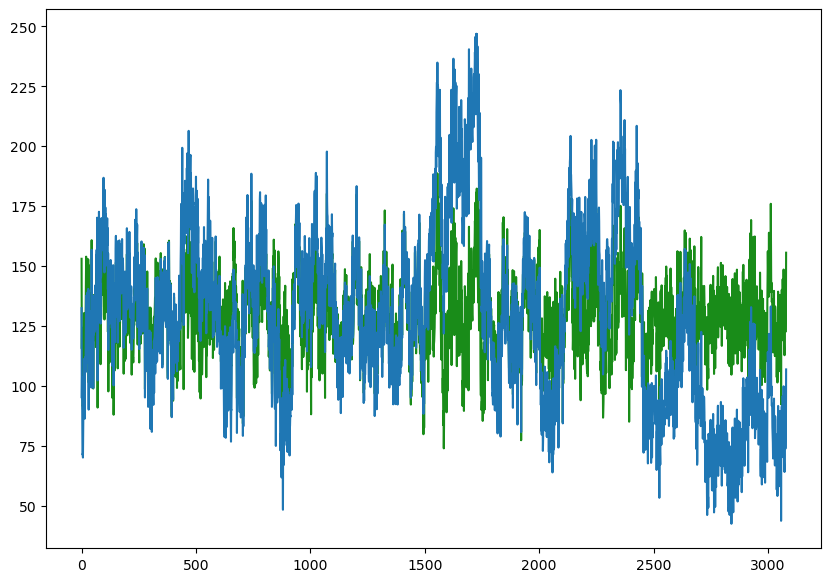

In [100]:
hpf(lctest.index.values, lctest['flux_hap_2'], plot=True)
plt.plot(lctest.index.values,lctest['flux_hap_2'])

In [105]:
folder_path = "/lustre/lrspec/ZTF_data/lightcurves/1020/"
save_path = '/lustre/lrspec/ZTF_data/lightcurves/1020_filtered/'

# # List all the files in the folder
files = [f for f in os.listdir(folder_path)]  # Adjust this to your file format
for file in files:
    lc = pd.read_csv(folder_path+file)
    filtered2 = hpf(lctest.index.values, lctest['flux_hap_2'], plot=False)
    filtered3 = hpf(lctest.index.values, lctest['flux_hap_3'], plot=False)
    newname2 = save_path + file[:-4]+"_filtered_hap2.csv"
    newname3 = save_path + file[:-4]+"_filtered_hap3.csv"
    filtered2.to_csv(newname2)
    filtered3.to_csv(newname3)

/tmp/ipykernel_53616/3887690766.py:6: DeprecationWarning: Please use `convolve1d` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  ga = filters.convolve1d(y, b/b.sum())
/tmp/ipykernel_53616/3887690766.py:6: DeprecationWarning: Please use `convolve1d` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  ga = filters.convolve1d(y, b/b.sum())
/tmp/ipykernel_53616/3887690766.py:6: DeprecationWarning: Please use `convolve1d` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  ga = filters.convolve1d(y, b/b.sum())
/tmp/ipykernel_53616/3887690766.py:6: DeprecationWarning: Please use `convolve1d` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  ga = filters.convolve1d(y, b/b.sum())
/tmp/ipykernel_53616/3887690766.py:6: DeprecationWarning: Please use `convolve1d` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace 

KeyboardInterrupt: 

In [106]:
thing

0       153.065884
1       115.549041
2       124.269547
3       110.482652
4        91.808801
           ...    
3075    143.745009
3076    122.543578
3077    132.139758
3078    129.504911
3079    155.604478
Name: flux_hap_2, Length: 3080, dtype: float64

In [112]:
column_names_dimming = ['snr_local_dimming', 'snr_global_dimming', 'noise_local_dimming', 'noise_global_dimming', 
                'local_average_outside_dimming', 'height_dimming', 'FWHM_dimming', 'signal_local_dimming', 'central_point_dimming']
# column_names_dimming = column_names_dimming +np.full( len(column_names_dimming),


In [113]:
column_names_dimming

array(['snr_local_dimming_filtered2', 'snr_global_dimming_filtered2',
       'noise_local_dimming_filtered2', 'noise_global_dimming_filtered',
       'local_average_outside_dimming', 'height_dimming_filtered2',
       'FWHM_dimming_filtered2', 'signal_local_dimming_filtered',
       'central_point_dimming_filtere'], dtype='<U29')

In [129]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [148]:
concat[(concat['filename']=='ztf_20221020157697_000640_zi_c16_x_0012.')*(concat['quad']==1)]

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,...,noise_global_dimming,local_average_outside_dimming,height_dimming,FWHM_dimming,signal_local_dimming,central_point_dimming,quadrant,num_in_file_in_star,global_noise_over_average,concat_index_copy
340903,340903,0,6,ztf_20221020157697_000640_zi_c16_x_0012.,1,neg,2402.000000,709.500000,2,718.0,...,14.876739,316.582624,-38.380232,1.0,6.195178,2414.0,1,1.0,0.046893,340903
340904,340904,1,4,ztf_20221020157697_000640_zi_c16_x_0012.,1,neg,937.833333,1561.166667,6,1571.0,...,16.131225,381.376740,-54.824310,1.0,7.404344,947.0,1,1.0,0.042371,340904
340905,340905,2,1,ztf_20221020157697_000640_zi_c16_x_0012.,1,pos,1271.000000,1771.000000,15,1781.0,...,82.186823,2983.654951,-88.728926,2.0,12.746441,1272.0,1,1.0,0.027534,340905
340906,340906,3,3,ztf_20221020157697_000640_zi_c16_x_0012.,1,neg,83.800000,1977.200000,5,1987.0,...,20.351410,594.666105,-45.432218,2.0,9.373701,96.0,1,2.0,0.034221,340906
340907,340907,4,5,ztf_20221020157697_000640_zi_c16_x_0012.,1,neg,1894.500000,1979.000000,2,1987.0,...,20.331137,590.203177,-44.387443,9.0,16.740207,1905.0,1,2.0,0.034437,340907


In [128]:
rff.get_tot_csv(concat,332122)[0]

0       149.722656
1       154.025238
2       132.173126
3       141.286530
4       153.327728
           ...    
3075    137.239014
3076    156.359985
3077    143.074524
3078    133.045624
3079    120.256073
Name: flux_hap_2, Length: 3080, dtype: float64

In [211]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [204]:
# Source - https://stackoverflow.com/q/28207743
# Posted by Am1rr3zA, modified by community. See post 'Timeline' for change history
# Retrieved 2026-06-01, License - CC BY-SA 4.0

np.fromstring('[686.5, 686.5]'[1:-1], dtype=float, sep=',')


array([686.5, 686.5])

In [207]:
np.fromstring('[686.5]'[1:-1], dtype=float, sep=',')

array([686.5])

In [214]:
concat

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,...,noise_global_dimming,local_average_outside_dimming,height_dimming,FWHM_dimming,signal_local_dimming,central_point_dimming,quadrant,num_in_file_in_star,global_noise_over_average,concat_index_copy
0,0,0,0,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,686.500000,907.000000,2,919.0,...,171.717937,6334.883496,-263.138867,2.0,20.657016,703.0,4,6.0,0.027036,0
1,1,1,3,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,1163.312500,908.625000,16,919.0,...,173.840620,6286.510950,-252.650110,3.0,25.764495,1168.0,4,6.0,0.027538,1
2,2,2,4,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,2080.173913,909.000000,23,919.0,...,170.488499,6321.075952,-37.555444,1.0,6.128250,2082.0,4,6.0,0.026951,2
3,3,3,6,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,2457.625000,909.375000,8,919.0,...,170.457841,6331.314060,-165.742283,2.0,16.219192,2461.0,4,6.0,0.026978,3
4,4,4,7,ztf_20221020141806_000686_zi_c11_x_0017.,4,both,2561.500000,908.000000,6,919.0,...,170.003755,6372.875215,-509.109590,2.0,31.840958,2578.0,4,6.0,0.026679,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347419,347419,49,77,ztf_20221020157697_000640_zi_c05_x_0024.,3,neg,824.500000,2703.000000,2,2714.0,...,37.040312,1004.303713,-121.429384,2.0,14.854293,833.0,3,7.0,0.037060,347419
347420,347420,50,34,ztf_20221020157697_000640_zi_c05_x_0024.,3,both,1247.214286,2904.642857,13,2913.0,...,16.063058,338.402133,-60.982577,4.0,14.286691,1253.0,3,2.0,0.047378,347420
347421,347421,51,39,ztf_20221020157697_000640_zi_c05_x_0024.,3,both,1350.156250,2904.000000,21,2913.0,...,16.210222,334.067805,-33.243006,1.0,5.765675,1366.0,3,2.0,0.048034,347421
347422,347422,0,0,ztf_20221020294271_000449_zr_c04_x_0003.,1,pos,830.857143,1381.857143,14,1392.0,...,229.755277,11174.133823,-432.334995,2.0,27.397520,830.0,1,1.0,0.020558,347422


In [215]:
pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat_with_band')

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,...,noise_local_dimming,noise_global_dimming,local_average_outside_dimming,height_dimming,FWHM_dimming,signal_local_dimming,central_point_dimming,quadrant,num_in_file_in_star,Band
0,0,0,0,0,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,686.500000,907.000000,2,...,216.645045,171.717937,6334.883496,-263.138867,2.0,20.657016,703.0,4,6.0,i
1,1,1,1,3,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,1163.312500,908.625000,16,...,157.363985,173.840620,6286.510950,-252.650110,3.0,25.764495,1168.0,4,6.0,i
2,2,2,2,4,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,2080.173913,909.000000,23,...,136.800273,170.488499,6321.075952,-37.555444,1.0,6.128250,2082.0,4,6.0,i
3,3,3,3,6,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,2457.625000,909.375000,8,...,179.325276,170.457841,6331.314060,-165.742283,2.0,16.219192,2461.0,4,6.0,i
4,4,4,4,7,ztf_20221020141806_000686_zi_c11_x_0017.,4,both,2561.500000,908.000000,6,...,166.683383,170.003755,6372.875215,-509.109590,2.0,31.840958,2578.0,4,6.0,i
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347419,347419,347419,49,77,ztf_20221020157697_000640_zi_c05_x_0024.,3,neg,824.500000,2703.000000,2,...,39.331224,37.040312,1004.303713,-121.429384,2.0,14.854293,833.0,3,7.0,i
347420,347420,347420,50,34,ztf_20221020157697_000640_zi_c05_x_0024.,3,both,1247.214286,2904.642857,13,...,15.551740,16.063058,338.402133,-60.982577,4.0,14.286691,1253.0,3,2.0,i
347421,347421,347421,51,39,ztf_20221020157697_000640_zi_c05_x_0024.,3,both,1350.156250,2904.000000,21,...,18.688348,16.210222,334.067805,-33.243006,1.0,5.765675,1366.0,3,2.0,i
347422,347422,347422,0,0,ztf_20221020294271_000449_zr_c04_x_0003.,1,pos,830.857143,1381.857143,14,...,204.000038,229.755277,11174.133823,-432.334995,2.0,27.397520,830.0,1,1.0,r


In [212]:
df3 = rff.add_snr_both_filtered_hap3(concat[:29])

In [213]:
df3

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,...,signal_local_brightening_filtered,central_point_brightening_filtere,snr_local_dimming_filtered3,snr_global_dimming_filtered3,noise_local_dimming_filtered3,noise_global_dimming_filtered,height_dimming_filtered3,FWHM_dimming_filtered3,signal_local_dimming_filtered,central_point_dimming_filtere
0,0,0,0,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,686.500000,907.000000,2,919.0,...,24.418436,684.0,0.101752,0.101650,295.090648,295.387398,-356.194423,3.0,30.026146,690.0
1,1,1,3,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,1163.312500,908.625000,16,919.0,...,21.639624,1171.0,0.161336,0.142048,261.348651,296.834956,-472.117198,5.0,42.164851,1160.0
2,2,2,4,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,2080.173913,909.000000,23,919.0,...,43.725899,2087.0,0.034768,0.037058,311.261867,292.028027,-117.115640,1.0,10.821998,2070.0
3,3,3,6,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,2457.625000,909.375000,8,919.0,...,23.017413,2452.0,0.194527,0.183435,278.763101,295.620746,-680.929089,6.0,54.227081,2461.0
4,4,4,7,ztf_20221020141806_000686_zi_c11_x_0017.,4,both,2561.500000,908.000000,6,919.0,...,22.647029,2564.0,0.054149,0.056725,308.889018,294.863914,-279.760163,1.0,16.726032,2562.0
5,5,5,11,ztf_20221020141806_000686_zi_c11_x_0017.,4,both,2925.125000,908.375000,8,919.0,...,43.474531,2932.0,0.054220,0.060414,326.933526,293.414164,-314.219790,1.0,17.726246,2927.0
6,6,6,5,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,2213.500000,1236.000000,8,1246.0,...,12.492586,2209.0,0.146631,0.150239,69.125941,67.466039,-102.738819,1.0,10.136016,2218.0
7,7,7,14,ztf_20221020141806_000686_zi_c11_x_0017.,4,neg,280.000000,1236.000000,3,1246.0,...,15.054064,281.0,0.442498,0.429779,66.372919,68.337232,-167.020450,7.0,29.369915,287.0
8,8,0,19,ztf_20221020148032_000686_zg_c14_x_0017.,1,pos,1849.000000,1058.500000,2,1069.0,...,48.847038,1858.0,0.103298,0.118028,351.390770,307.536262,-490.685342,3.0,36.297812,1852.0
9,9,1,25,ztf_20221020148032_000686_zg_c14_x_0017.,1,pos,2581.850000,1058.200000,20,1069.0,...,66.674136,2590.0,0.079356,0.079321,308.104160,308.239707,-326.685203,2.0,24.449893,2573.0


In [131]:
rff.add_snr_both_filtered_hap2(concat.loc[332122])

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3505, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_53616/1194556116.py", line 1, in <module>
    rff.add_snr_both_filtered_hap2(concat.loc[332122])
  File "/home/3155/rwe/review_findings_functions.py", line 3557, in add_snr_both_filtered_hap2
    for filename, filenamegroup in df.groupby('filename'):
                                 ^^^^^^^^^^^^^^^^^^^^^^
  File "/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/pandas/core/series.py", line 2076, in groupby
    return SeriesGroupBy(
           ^^^^^^^^^^^^^^
  File "/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/pandas/core/groupby/groupby.py", line 965, in __init__
    grouper, exclusions, obj = get_grouper(
                               ^^^^^^^^^^^^
  File "/lustre/lrspec/users/3

In [173]:
for i, row in concat[:29].iterrows():
    thing = rff.get_tot_csv_filtered_hap2(concat,i)

In [216]:
concat_filt = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat_filtered')

In [219]:
concat2 = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat_filtered2')

In [226]:
concat2.drop(columns=['Unnamed: 0.4','Unnamed: 0.3','Unnamed: 0.2'])['signal_local_brightening_filtered']

0         33.546914
1         35.922804
2         60.409007
3         41.903888
4         19.478741
            ...    
347419    13.941769
347420     7.531349
347421    14.189560
347422    55.677669
347423     7.240273
Name: signal_local_brightening_filtered, Length: 347424, dtype: float64

In [227]:
concat2.iloc[0]

Unnamed: 0.4                                                                0
Unnamed: 0.3                                                                0
Unnamed: 0.2                                                                0
Unnamed: 0.1                                                                0
Unnamed: 0                                                                  0
filename                             ztf_20221020141806_000686_zi_c11_x_0017.
quad                                                                        4
type                                                                      pos
row_from_nn                                                             686.5
col_from_nn                                                             907.0
detection_size                                                              2
closest_x                                                               919.0
closest_y                                                       

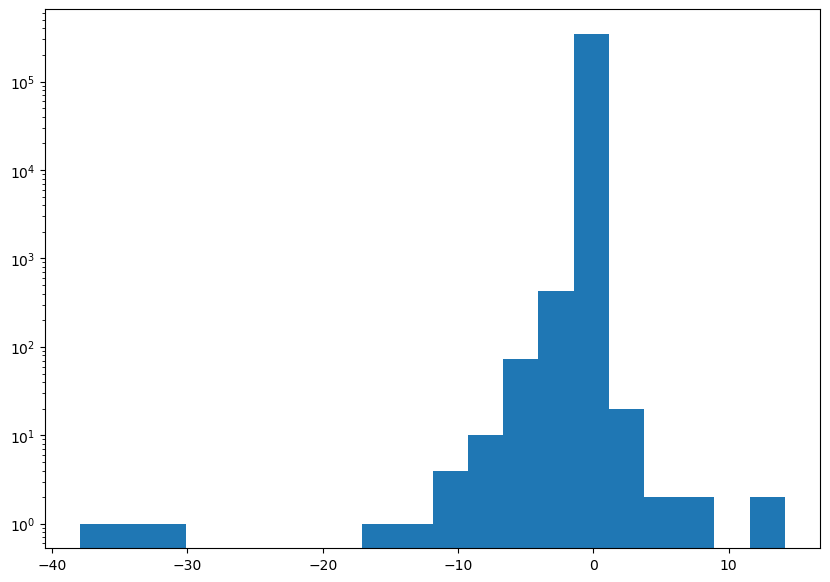

In [230]:
plt.hist(concat2['snr_local_brightening_filtered2']-concat2['snr_local_brightening'], bins=20)
plt.yscale('log')